In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

# Workstream D — Degrees, paths and reachability (Project 4)

Question: how is the graph connected, and what does a threshold do to its paths?
Items D-1 … D-7 of the Week 3 EDA Plan, on **fafb** (FlyWire 783, annotations v3.2.0, Buhmann synapses)
and **malecns** (male-cns v1.0, Traced, synapse confidence ≥ 0.5, **brain part only**: `in_brain == True`
from `add_provisional_flags` with the VNC-branch ROIs as `nerve_cord`, and the edges among those neurons).

Everything is read from `data/cache/` (no network calls). Thresholds are applied in memory to the
1-synapse cache; relative weights come from `eda_shared.relative_weight`, computed at τ = 1 and filtered after.
Graphs use `scipy.sparse` with orientation **row = pre_id (sender), column = post_id (receiver)**.

In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt

import config
from eda_shared.eda_helpers import basic_features, relative_weight
from eda_shared.randomiser import randomise_edges, reciprocity
from src.fetch import load
from src.provisional import flag

FIG = ROOT / "figures" / "eda"
TAB = ROOT / "reports" / "eda_D_tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
# pandas FutureWarning raised inside eda_shared (add_provisional_flags: fillna downcasting); harmless here
warnings.filterwarnings("ignore", message="Downcasting object dtype arrays", category=FutureWarning)

# Threshold grid (Definitions): absolute tau, then relative fraction of the target's input.
THRESHOLDS = [("abs", 1), ("abs", 5), ("abs", 10), ("abs", 31), ("rel", 0.009), ("rel", 0.026)]
def thr_label(t): return f"≥{t[1]}" if t[0] == "abs" else f"{t[1]*100:.1f}%"
def thr_tag(t): return f"min{t[1]}" if t[0] == "abs" else f"rel{t[1]*100:.1f}"
TAU = ("abs", 10)                                     # default where an item does not vary tau

# Colours (validated categorical palette, fixed order): identity follows the entity.
DS_COL = {"fafb": "#2a78d6", "malecns": "#eb6834"}
POP_COL = {"all": "#52514e", "central": "#1baf7a", "optic": "#4a3aa7"}
SET_COL = {"reachable": "#1baf7a", "unreachable": "#4a3aa7"}
OTHER = "#b5b3ad"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2})

In [3]:
VNC = (ROOT / "reports" / "malecns_nerve_cord_rois.txt").read_text().split()
KEEP = ["neuron_id", "cell_type", "cell_class", "super_class", "region", "neuropil",
        "is_optic", "region_group", "in_brain"]

f = load("fafb")
fafb_neurons = flag(f["neurons"])                    # fafb: never filtered by in_brain (UNASGD stays)
m = load("malecns")
malecns_cns = flag(m["neurons"], nerve_cord=VNC)
brain = malecns_cns[malecns_cns["in_brain"]].reset_index(drop=True)
ids = brain["neuron_id"]
malecns_edges = m["edges"][m["edges"]["pre_id"].isin(ids) & m["edges"]["post_id"].isin(ids)].reset_index(drop=True)

DATA = {
    "fafb": {"neurons": fafb_neurons, "edges": f["edges"], "tag": "fafb_783",
             "label": "FAFB 783 (annotations v3.2.0, Buhmann synapses)"},
    "malecns": {"neurons": brain, "edges": malecns_edges, "tag": "malecns_v1.0",
                "label": "MaleCNS v1.0 (Traced, conf ≥ 0.5, brain only)"},
}
for ds, d in DATA.items():
    d["edges"] = d["edges"].copy()
    d["edges"]["frac"] = relative_weight(d["edges"])   # at tau = 1, before any filtering
    print(f"{ds}: {len(d['neurons']):,} neurons, {len(d['edges']):,} edges at τ = 1 "
          f"(central {(~d['neurons'].is_optic).sum():,}, optic {d['neurons'].is_optic.sum():,})")
print(f"malecns full CNS: {len(malecns_cns):,} neurons, {len(m['edges']):,} edges; brain set {len(brain):,}")

fafb: 139,255 neurons, 15,091,983 edges at τ = 1 (central 44,487, optic 94,768)


malecns: 142,757 neurons, 21,361,769 edges at τ = 1 (central 43,988, optic 98,769)
malecns full CNS: 165,122 neurons, 25,563,096 edges; brain set 142,757


In [4]:
def kept(edges, t):
    return edges[edges["syn_count"] >= t[1]] if t[0] == "abs" else edges[edges["frac"] >= t[1]]

def features(ds, t):
    """basic_features for absolute tau; the same degree counts for a relative threshold."""
    d = DATA[ds]
    if t[0] == "abs":
        F = basic_features(d["neurons"], d["edges"].drop(columns="frac"), tau=t[1])
    else:
        k = kept(d["edges"], t)
        F = pd.DataFrame({"neuron_id": d["neurons"]["neuron_id"]}).set_index("neuron_id")
        F["in_degree"] = k.groupby("post_id").size()
        F["out_degree"] = k.groupby("pre_id").size()
        F = F.fillna(0).astype("int64").reset_index()
    return F.merge(d["neurons"][KEEP], on="neuron_id", validate="one_to_one")

POPS = {"all": lambda F: np.ones(len(F), bool), "central": lambda F: ~F["is_optic"].to_numpy(),
        "optic": lambda F: F["is_optic"].to_numpy()}

def ccdf(values, n_total=None):
    """Share of items with value >= x, for every observed x >= 1 (denominator: all items)."""
    v = np.sort(np.asarray(values))
    n = len(v) if n_total is None else n_total
    x = np.unique(v[v >= 1])
    return x, (len(v) - np.searchsorted(v, x, "left")) / n

def caption(fig, text, y=-0.02):
    fig.text(0.01, y, text, ha="left", va="top", fontsize=8.5, color="#52514e", wrap=True)

def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    print("saved figures/eda/" + name)

def adjacency(ds, t):
    """CSR matrix A with A[i, j] = 1 if neuron i -> neuron j survives threshold t (row = pre)."""
    d = DATA[ds]
    index = pd.Index(d["neurons"]["neuron_id"])
    k = kept(d["edges"], t)
    i, j = index.get_indexer(k["pre_id"]), index.get_indexer(k["post_id"])
    n = len(index)
    return sp.csr_matrix((np.ones(len(k), np.int8), (i, j)), shape=(n, n))

def bfs_depth(A, seeds):
    """Multi-source BFS along edge direction (pre -> post); -1 = unreachable."""
    depth = np.full(A.shape[0], -1, np.int32)
    frontier = np.flatnonzero(seeds)
    depth[frontier] = 0
    d = 0
    while frontier.size:
        d += 1
        nxt = np.unique(A[frontier].indices)
        nxt = nxt[depth[nxt] < 0]
        depth[nxt] = d
        frontier = nxt
    return depth

## D-1. Degree distributions
features at τ = 10, both datasets, populations all / central / optic. CCDF of in- and out-degree,
both axes log; colour = population, solid = in-degree, dashed = out-degree; panels = dataset.
Shares use every neuron of the population as denominator (neurons with degree 0 are in the denominator
but cannot be drawn on a log axis).

saved figures/eda/D-1_fafb_783_malecns_v1.0_all-central-optic_min10.png


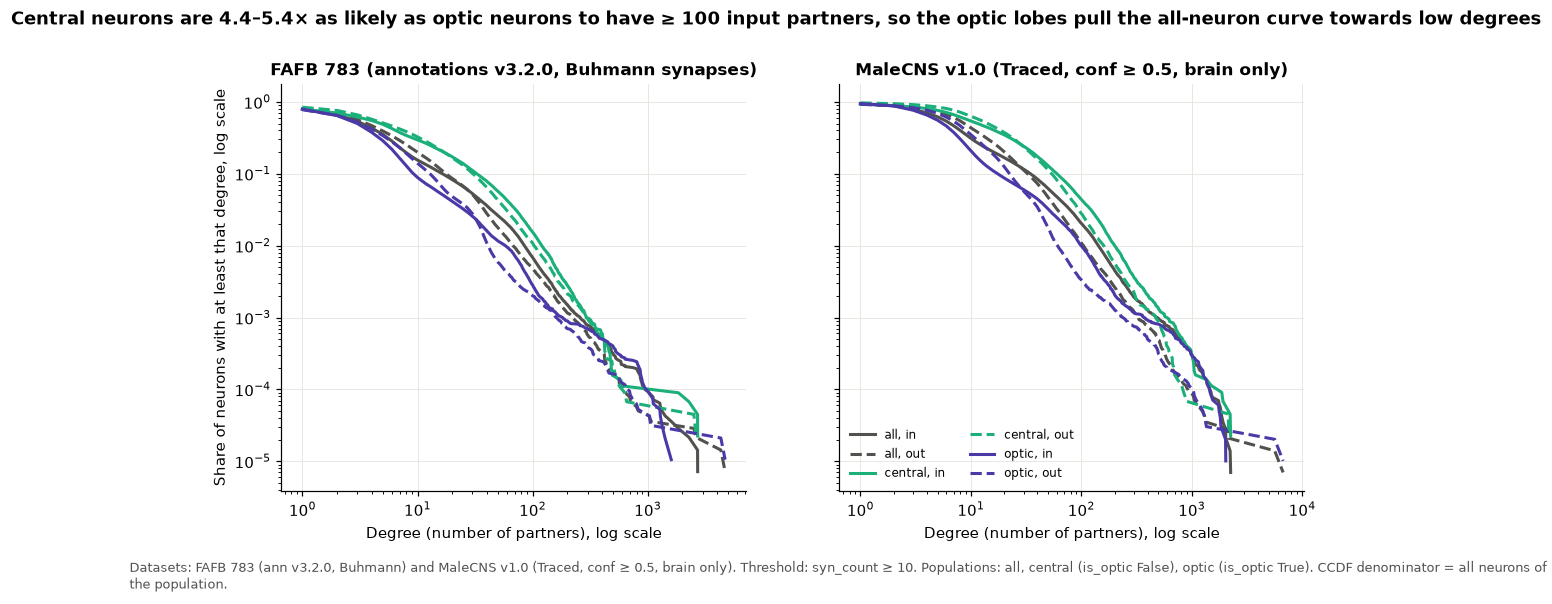

,dataset,population,degree,neurons,zero_%,median,mean,p99,max,share_ge_100_%
0,fafb,all,in_degree,139255,20.78,3.0,7.66,85.00,2716,0.685
1,fafb,all,out_degree,139255,20.20,3.0,7.66,67.00,4704,0.484
2,fafb,central,in_degree,44487,20.69,4.0,12.68,119.14,2716,1.540
3,fafb,central,out_degree,44487,15.76,5.0,12.05,102.00,2630,1.088
4,fafb,optic,in_degree,94768,20.82,3.0,5.30,57.00,1601,0.284
5,fafb,optic,out_degree,94768,22.29,3.0,5.60,41.00,4704,0.200
6,malecns,all,in_degree,142757,5.84,6.0,14.98,142.00,2253,2.045
7,malecns,all,out_degree,142757,6.19,8.0,14.98,104.00,6727,1.096
8,malecns,central,in_degree,43988,7.21,11.0,25.48,200.00,2253,4.401
9,malecns,central,out_degree,43988,3.08,14.0,24.04,159.00,2159,2.803


In [5]:
F10 = {ds: features(ds, TAU) for ds in DATA}
rows, pts = [], []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, (ds, F) in zip(axes, F10.items()):
    for pop, sel in POPS.items():
        P = F[sel(F)]
        for col, ls in (("in_degree", "-"), ("out_degree", "--")):
            x, y = ccdf(P[col])
            ax.plot(x, y, ls, color=POP_COL[pop], label=f"{pop}, {col.split('_')[0]}")
            pts.append(pd.DataFrame({"dataset": ds, "population": pop, "degree": col, "x": x, "share_ge_x": y}))
            v = P[col]
            rows.append({"dataset": ds, "population": pop, "degree": col, "neurons": len(P),
                         "zero_%": round(100 * (v == 0).mean(), 2), "median": v.median(),
                         "mean": round(v.mean(), 2), "p99": v.quantile(0.99), "max": v.max(),
                         "share_ge_100_%": round(100 * (v >= 100).mean(), 3)})
    ax.set(xscale="log", yscale="log", xlabel="Degree (number of partners), log scale",
           title=DATA[ds]["label"])
axes[0].set_ylabel("Share of neurons with at least that degree, log scale")
axes[1].legend(fontsize=8, ncol=2, frameon=False, loc="lower left")
D1 = pd.DataFrame(rows)
pd.concat(pts).to_csv(TAB / "D-1_ccdf_points.csv", index=False)
D1.to_csv(TAB / "D-1_degree_summary.csv", index=False)
g = D1.set_index(["dataset", "population", "degree"])
ratio = {ds: g.loc[(ds, 'central', 'in_degree'), 'share_ge_100_%'] / g.loc[(ds, 'optic', 'in_degree'), 'share_ge_100_%']
         for ds in DATA}
fig.suptitle((
    f"Central neurons are {min(ratio.values()):.1f}–{max(ratio.values()):.1f}× as likely as optic neurons to have ≥ 100 "
    "input partners, so the optic lobes pull the all-neuron curve towards low degrees"),
    y=1.02, fontsize=11.5, fontweight="bold")
caption(fig, "Datasets: FAFB 783 (ann v3.2.0, Buhmann) and MaleCNS v1.0 (Traced, conf ≥ 0.5, brain only). "
        "Threshold: syn_count ≥ 10. Populations: all, central (is_optic False), optic (is_optic True). "
        "CCDF denominator = all neurons of the population.")
save(fig, "D-1_fafb_783_malecns_v1.0_all-central-optic_min10.png")
plt.show()
D1

## D-2. Hubs
features at τ = 10, central. Hubs = top 1% of central neurons by in_degree + out_degree
(sorted by total degree, ties broken by neuron_id). Scatter of log(1 + in) vs log(1 + out), a random
20,000 neurons (seed 0) coloured by super_class (three largest classes; the rest grey), hubs ringed in black.

saved figures/eda/D-2_fafb_783_central_min10.png


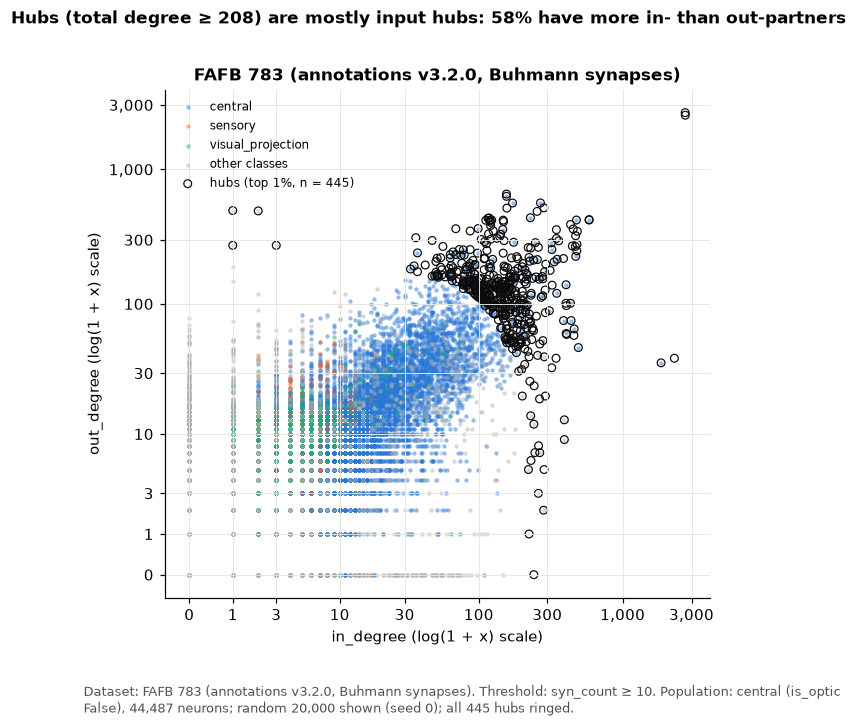

saved figures/eda/D-2_malecns_v1.0_central_min10.png


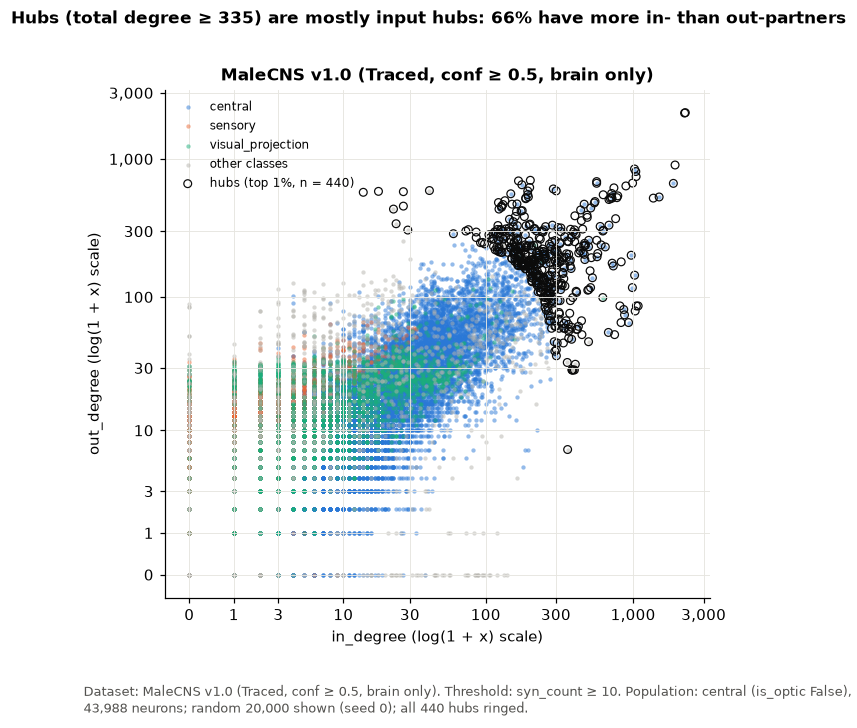

,0,1
dataset,fafb,malecns
central_neurons,44487,43988
hubs,445,440
cutoff_total_degree,208,335
ties_at_cutoff_left_out,0,0
hubs_out_gt_in_%,41.6,33.6
hubs_in_gt_out_%,57.5,66.4
median_out_over_in,0.89,0.75
top_super_classes,"{'central': 400, 'descending': 40, 'ascending'...","{'central': 396, 'descending': 29, 'ascending'..."
top_cell_types,"{'lLN2X03': 5, 'AOTU041': 4, 'lLN2F_b': 4, 'PL...","{'lLN1_bc': 6, 'lLN2T_a': 5, 'lLN2T_b': 4, 'AO..."


In [6]:
hub_rows, hub_summary = [], []
for ds, F in F10.items():
    C = F[~F["is_optic"]].copy()
    C["total_degree"] = C["in_degree"] + C["out_degree"]
    k = int(round(0.01 * len(C)))
    C = C.sort_values(["total_degree", "neuron_id"], ascending=[False, True])
    hubs = C.head(k)
    cutoff = hubs["total_degree"].min()
    tied_out = int((C["total_degree"].iloc[k:] == cutoff).sum())
    hubs.assign(dataset=ds)[["dataset", "neuron_id", "cell_type", "super_class", "region",
                             "in_degree", "out_degree", "total_degree"]].to_csv(
        TAB / f"D-2_hubs_{DATA[ds]['tag']}_central_min10.csv", index=False)
    s = {"dataset": ds, "central_neurons": len(C), "hubs": k, "cutoff_total_degree": int(cutoff),
         "ties_at_cutoff_left_out": tied_out,
         "hubs_out_gt_in_%": round(100 * (hubs.out_degree > hubs.in_degree).mean(), 1),
         "hubs_in_gt_out_%": round(100 * (hubs.in_degree > hubs.out_degree).mean(), 1),
         "median_out_over_in": round((hubs.out_degree / hubs.in_degree.clip(lower=1)).median(), 2),
         "top_super_classes": hubs.super_class.astype(str).value_counts().head(4).to_dict(),
         "top_cell_types": hubs.cell_type.fillna("(no type)").value_counts().head(8).to_dict(),
         "top_regions": hubs.region.value_counts().head(5).to_dict()}
    hub_summary.append(s)

    top3 = C["super_class"].astype(str).value_counts().index[:3].tolist()
    colors = dict(zip(top3, ["#2a78d6", "#eb6834", "#1baf7a"]))
    S = C.sample(min(20_000, len(C)), random_state=0)
    sc = S["super_class"].astype(str)
    fig, ax = plt.subplots(figsize=(6.4, 6))
    for cls in top3 + ["other"]:
        sel = sc.isin([cls]) if cls != "other" else ~sc.isin(top3)
        ax.scatter(np.log1p(S.loc[sel, "in_degree"]), np.log1p(S.loc[sel, "out_degree"]), s=8,
                   color=colors.get(cls, OTHER), alpha=0.5, lw=0, label=cls if cls != "other" else "other classes")
    ax.scatter(np.log1p(hubs["in_degree"]), np.log1p(hubs["out_degree"]), s=26, facecolors="none",
               edgecolors="#0b0b0b", lw=0.8, label=f"hubs (top 1%, n = {k})")
    ax.set(xlabel="in_degree (log(1 + x) scale)", ylabel="out_degree (log(1 + x) scale)", title=DATA[ds]["label"])
    deg_ticks = [0, 1, 3, 10, 30, 100, 300, 1000, 3000]     # label ticks in partners, not in log units
    ax.set_xticks(np.log1p(deg_ticks), [f"{t:,}" for t in deg_ticks])
    ax.set_yticks(np.log1p(deg_ticks), [f"{t:,}" for t in deg_ticks])
    ax.legend(fontsize=8, frameon=False, loc="upper left")
    lead = "output" if s["hubs_out_gt_in_%"] > 50 else "input"
    fig.suptitle(f"Hubs (total degree ≥ {cutoff}) are mostly {lead} hubs: "
                 f"{max(s['hubs_out_gt_in_%'], s['hubs_in_gt_out_%']):.0f}% have more {'out' if lead == 'output' else 'in'}- than "
                 f"{'in' if lead == 'output' else 'out'}-partners",
                 y=1.0, fontsize=11, fontweight="bold")
    caption(fig, f"Dataset: {DATA[ds]['label']}. Threshold: syn_count ≥ 10. Population: central "
            f"(is_optic False), {len(C):,} neurons; random 20,000 shown (seed 0); all {k} hubs ringed.")
    save(fig, f"D-2_{DATA[ds]['tag']}_central_min10.png")
    plt.show()
D2 = pd.DataFrame(hub_summary)
D2.to_csv(TAB / "D-2_hub_summary.csv", index=False)
D2.T

## D-3. Neurons with no inputs or no outputs
features recomputed at each threshold, central. Share of central neurons with in_degree = 0, out_degree = 0
and both. The relative thresholds are drawn after a gap as labelled points.

saved figures/eda/D-3_fafb_783_malecns_v1.0_central_min1-31_rel0.9-2.6.png


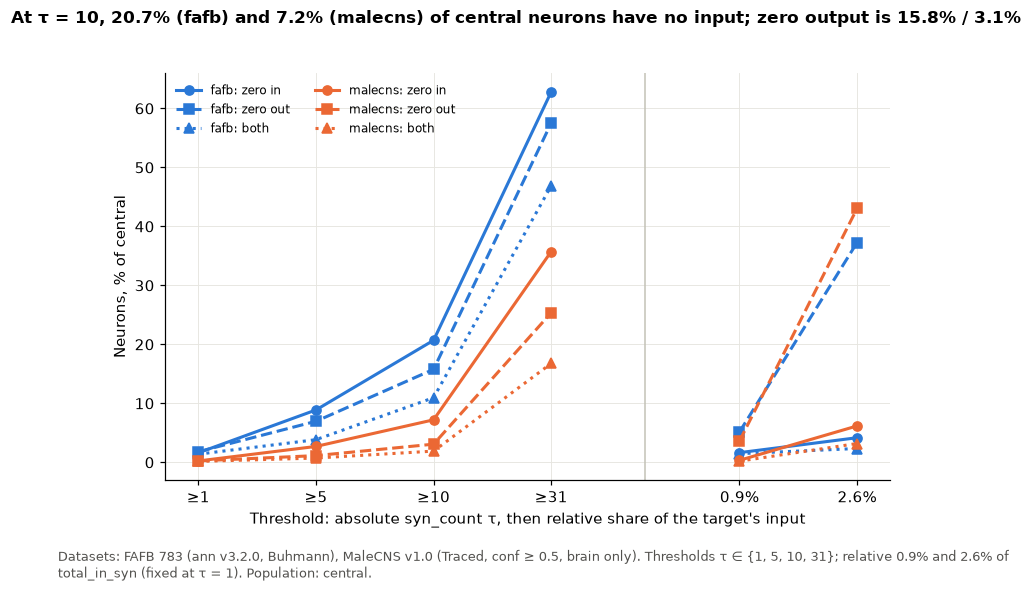

,dataset,threshold,central,zero_in,zero_out,both,zero_in_%,zero_out_%,both_%
0,fafb,≥1,44487,718,801,616,1.61,1.80,1.38
1,fafb,≥5,44487,3949,3094,1708,8.88,6.95,3.84
2,fafb,≥10,44487,9204,7013,4874,20.69,15.76,10.96
3,fafb,≥31,44487,27943,25592,20860,62.81,57.53,46.89
4,fafb,0.9%,44487,729,2283,653,1.64,5.13,1.47
5,fafb,2.6%,44487,1856,16577,1042,4.17,37.26,2.34
6,malecns,≥1,43988,102,106,66,0.23,0.24,0.15
7,malecns,≥5,43988,1185,501,319,2.69,1.14,0.73
8,malecns,≥10,43988,3170,1354,837,7.21,3.08,1.90
9,malecns,≥31,43988,15721,11155,7375,35.74,25.36,16.77


In [7]:
rows = []
FEATS = {}
for ds in DATA:
    for t in THRESHOLDS:
        F = features(ds, t)
        FEATS[(ds, t)] = F
        C = F[~F["is_optic"]]
        zin, zout = C.in_degree.eq(0), C.out_degree.eq(0)
        rows.append({"dataset": ds, "threshold": thr_label(t), "central": len(C),
                     "zero_in": int(zin.sum()), "zero_out": int(zout.sum()), "both": int((zin & zout).sum()),
                     "zero_in_%": 100 * zin.mean(), "zero_out_%": 100 * zout.mean(),
                     "both_%": 100 * (zin & zout).mean()})
D3 = pd.DataFrame(rows)
D3.round(2).to_csv(TAB / "D-3_zero_degree_central.csv", index=False)

xpos = {thr_label(t): x for t, x in zip(THRESHOLDS, [0, 1, 2, 3, 4.6, 5.6])}
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for ds in DATA:
    T = D3[D3.dataset == ds]
    for col, ls, mk in (("zero_in_%", "-", "o"), ("zero_out_%", "--", "s"), ("both_%", ":", "^")):
        a, r = T.iloc[:4], T.iloc[4:]
        ax.plot([xpos[x] for x in a.threshold], a[col], ls, marker=mk, ms=6, color=DS_COL[ds],
                label=f"{ds}: {col.replace('_%', '').replace('_', ' ')}")
        ax.plot([xpos[x] for x in r.threshold], r[col], ls, marker=mk, ms=6, color=DS_COL[ds])
ax.set_xticks(list(xpos.values()), list(xpos.keys()))
ax.axvline(3.8, color="#c3c2b7", lw=1)
ax.set(xlabel="Threshold: absolute syn_count τ, then relative share of the target's input",
       ylabel="Neurons, % of central")
ax.legend(fontsize=8, ncol=2, frameon=False)
v10 = D3[D3.threshold == "≥10"].set_index("dataset")
fig.suptitle(f"At τ = 10, {v10.loc['fafb','zero_in_%']:.1f}% (fafb) and {v10.loc['malecns','zero_in_%']:.1f}% (malecns) "
             f"of central neurons have no input; zero output is {v10.loc['fafb','zero_out_%']:.1f}% / "
             f"{v10.loc['malecns','zero_out_%']:.1f}%", y=1.0, fontsize=11, fontweight="bold")
caption(fig, "Datasets: FAFB 783 (ann v3.2.0, Buhmann), MaleCNS v1.0 (Traced, conf ≥ 0.5, brain only). "
        "Thresholds τ ∈ {1, 5, 10, 31}; relative 0.9% and 2.6% of total_in_syn (fixed at τ = 1). Population: central.")
save(fig, "D-3_fafb_783_malecns_v1.0_central_min1-31_rel0.9-2.6.png")
plt.show()
D3.round(2)

## D-4. Seed sets
Sensory seeds: `super_class == 'sensory'`; motor seeds: `super_class == 'motor'` (unknown never included).
Sensory counted by cell_class (modality; "(no class)" where missing); motor counted by region
(the canonical neuropil from eda_shared, so both datasets share one spelling).

seed     motor  sensory
dataset                
fafb       110    17516
malecns    107     9142


saved figures/eda/D-4_fafb_783_malecns_v1.0_all_nothreshold.png


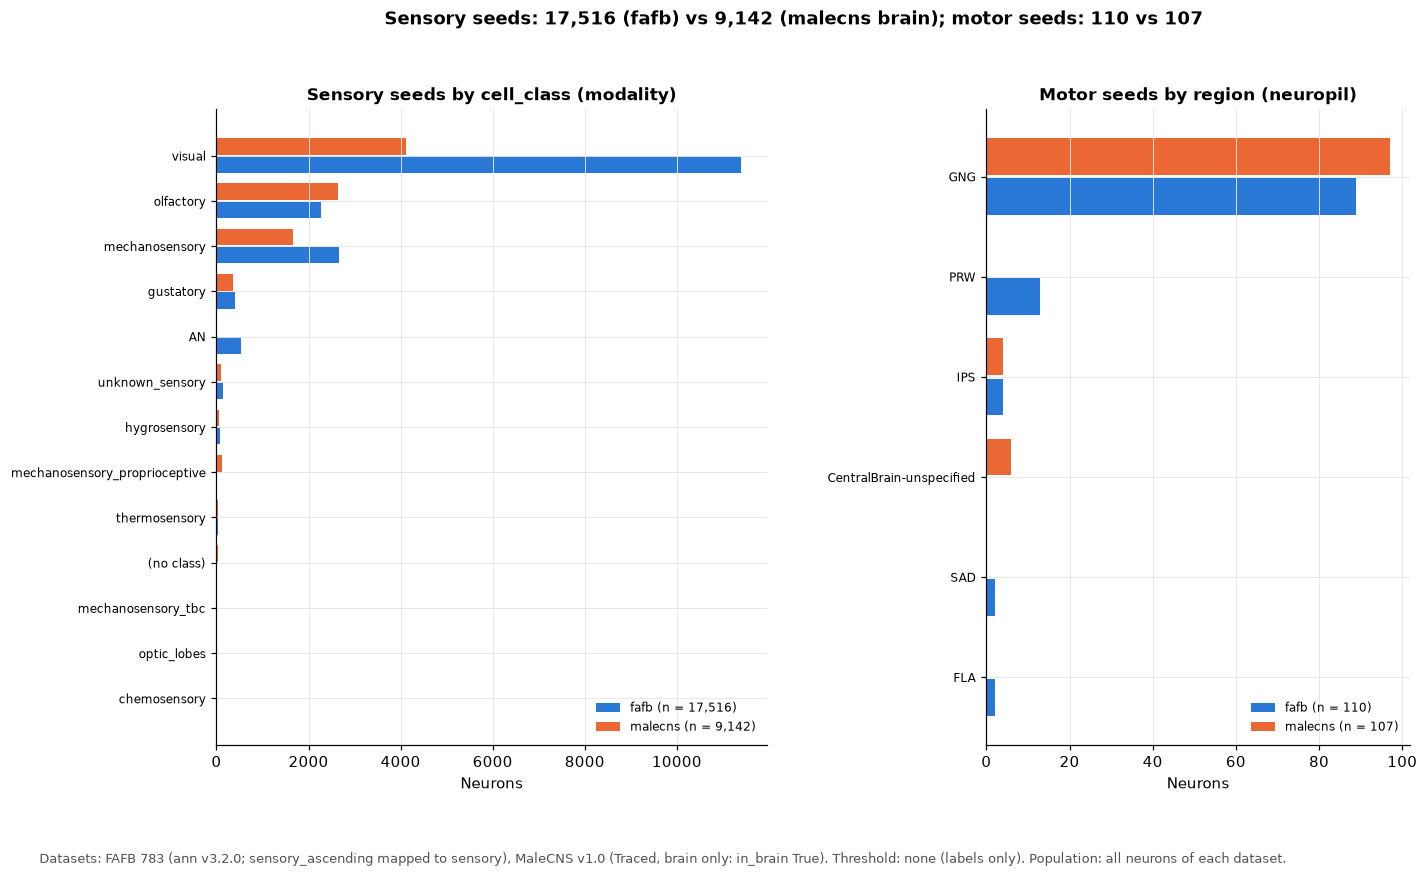

In [8]:
seed_rows = []
for ds, d in DATA.items():
    n = d["neurons"]
    s = n[n.super_class == "sensory"]
    mo = n[n.super_class == "motor"]
    seed_rows += [{"dataset": ds, "seed": "sensory", "group": g, "neurons": c}
                  for g, c in s.cell_class.fillna("(no class)").value_counts().items()]
    seed_rows += [{"dataset": ds, "seed": "motor", "group": g, "neurons": c}
                  for g, c in mo.neuropil.value_counts().items()]
D4 = pd.DataFrame(seed_rows)
D4.to_csv(TAB / "D-4_seed_sets.csv", index=False)
totals = D4.groupby(["dataset", "seed"]).neurons.sum().unstack()
print(totals)

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
for ax, seed in zip(axes, ["sensory", "motor"]):
    T = D4[D4.seed == seed].pivot_table(index="group", columns="dataset", values="neurons", fill_value=0)
    T = T.reindex(columns=list(DATA), fill_value=0)
    T = T.loc[T.sum(axis=1).sort_values().index]
    y = np.arange(len(T))
    h = 0.4
    for k, ds in enumerate(DATA):
        ax.barh(y + (k - 0.5) * h, T[ds], height=h * 0.92, color=DS_COL[ds],
                label=f"{ds} (n = {int(totals.loc[ds, seed]):,})")
    ax.set_yticks(y, T.index, fontsize=8)
    ax.set(xlabel="Neurons", title=f"{seed.capitalize()} seeds by "
           + ("cell_class (modality)" if seed == "sensory" else "region (neuropil)"))
    ax.legend(fontsize=8, frameon=False, loc="lower right")
fig.suptitle(f"Sensory seeds: {int(totals.loc['fafb','sensory']):,} (fafb) vs {int(totals.loc['malecns','sensory']):,} "
             f"(malecns brain); motor seeds: {int(totals.loc['fafb','motor'])} vs {int(totals.loc['malecns','motor'])}",
             y=1.0, fontsize=11.5, fontweight="bold")
caption(fig, "Datasets: FAFB 783 (ann v3.2.0; sensory_ascending mapped to sensory), MaleCNS v1.0 (Traced, brain only: "
        "in_brain True). Threshold: none (labels only). Population: all neurons of each dataset.")
save(fig, "D-4_fafb_783_malecns_v1.0_all_nothreshold.png")
plt.show()

## D-5. Reachability and depth
Breadth-first search along edge direction (pre → post) from all sensory neurons at once, on the whole graph
of each dataset (paths may pass through the optic lobes). Depth = fewest hops from any sensory neuron.
Reported population: central non-sensory neurons (is_optic False, super_class ≠ sensory).

BFS: 5.7 s


saved figures/eda/D-5_fafb_783_malecns_v1.0_central_min1-31_rel0.9-2.6.png


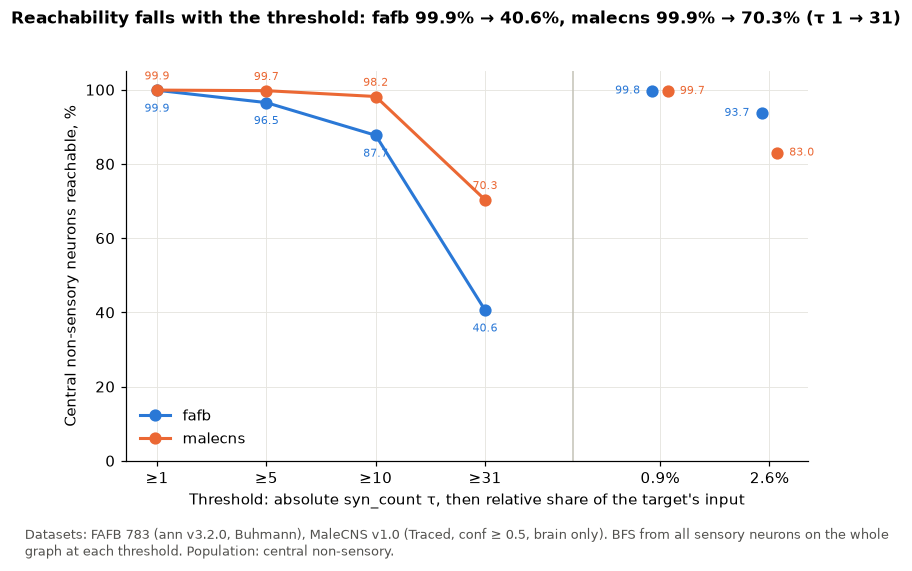

saved figures/eda/D-5_fafb_783_central_min1-31_rel0.9-2.6.png


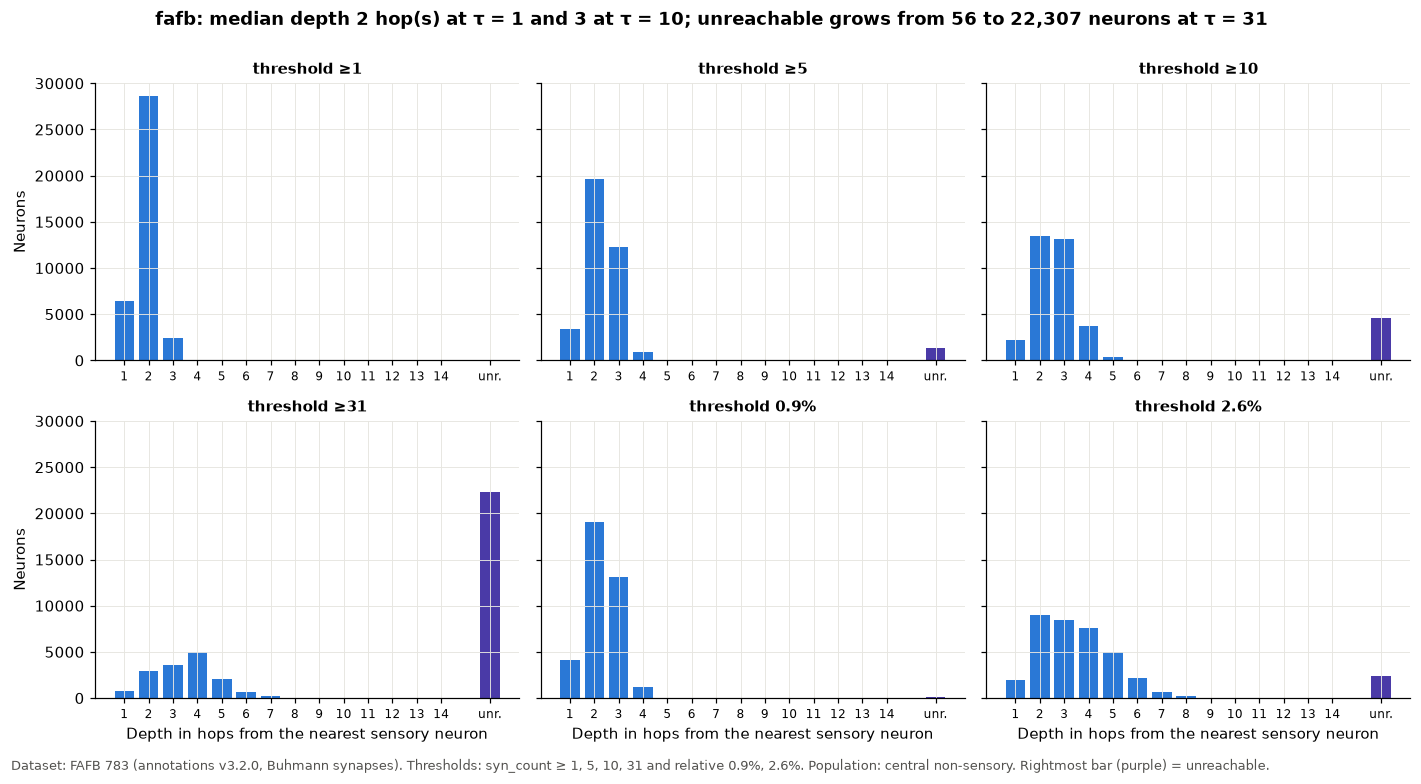

saved figures/eda/D-5_malecns_v1.0_central_min1-31_rel0.9-2.6.png


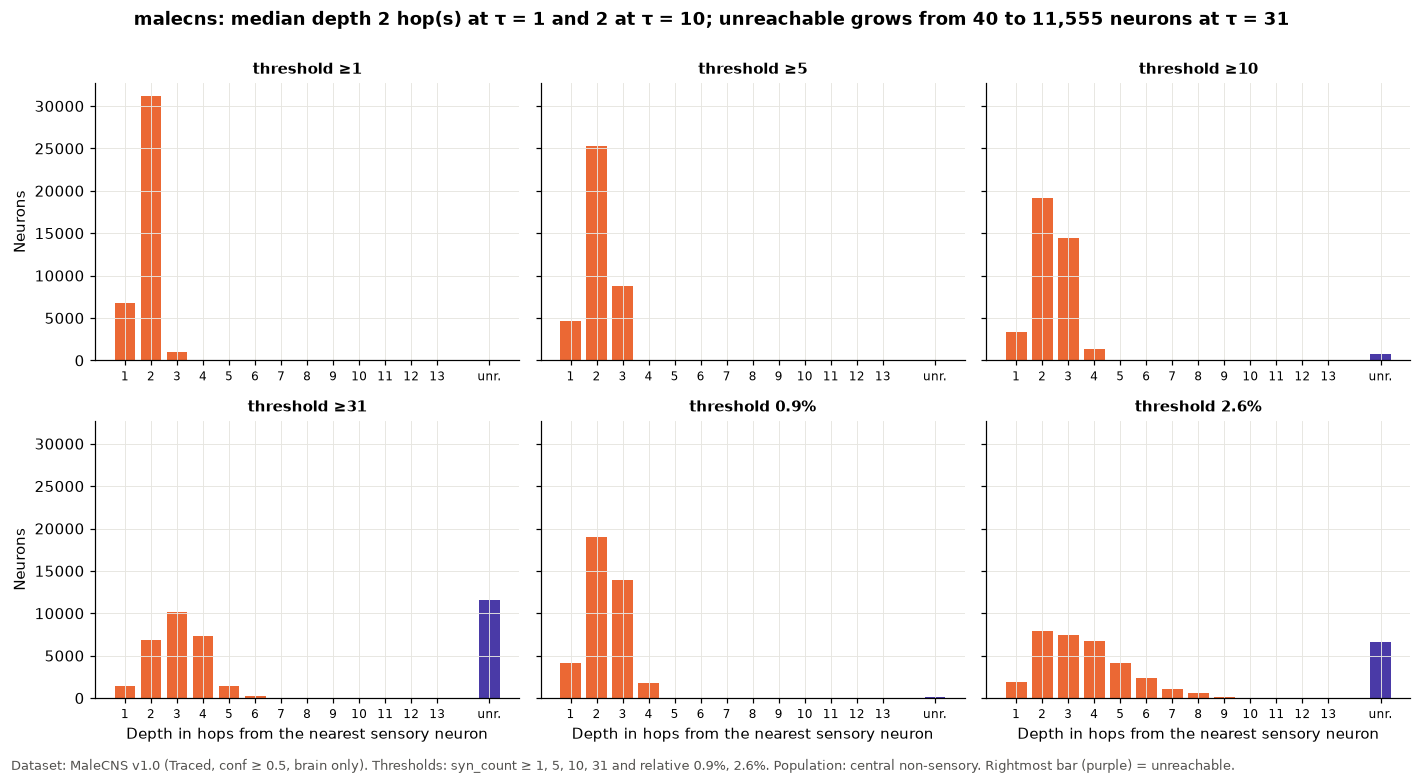

,dataset,threshold,central_non_sensory,reachable,reachable_%,unreachable,median_depth,max_depth
0,fafb,≥1,37556,37500,99.85,56,2.0,5
1,fafb,≥5,37556,36251,96.53,1305,2.0,6
2,fafb,≥10,37556,32941,87.71,4615,3.0,7
3,fafb,≥31,37556,15249,40.60,22307,4.0,13
4,fafb,0.9%,37556,37473,99.78,83,2.0,7
5,fafb,2.6%,37556,35205,93.74,2351,3.0,14
6,malecns,≥1,38960,38920,99.90,40,2.0,3
7,malecns,≥5,38960,38860,99.74,100,2.0,4
8,malecns,≥10,38960,38247,98.17,713,2.0,8
9,malecns,≥31,38960,27405,70.34,11555,3.0,9


In [9]:
DEPTH, rows, hist = {}, [], []
t0 = time.perf_counter()
for ds, d in DATA.items():
    n = d["neurons"]
    seeds = (n.super_class == "sensory").to_numpy()
    target = (~n.is_optic & (n.super_class != "sensory")).to_numpy()
    for t in THRESHOLDS:
        depth = bfs_depth(adjacency(ds, t), seeds)
        DEPTH[(ds, t)] = depth
        dt = depth[target]
        rows.append({"dataset": ds, "threshold": thr_label(t), "central_non_sensory": int(target.sum()),
                     "reachable": int((dt >= 0).sum()), "reachable_%": 100 * (dt >= 0).mean(),
                     "unreachable": int((dt < 0).sum()), "median_depth": float(np.median(dt[dt >= 0])),
                     "max_depth": int(dt.max())})
        h = pd.Series(dt).value_counts().sort_index()
        hist.append(pd.DataFrame({"dataset": ds, "threshold": thr_label(t),
                                  "depth": ["unreachable" if i < 0 else int(i) for i in h.index],
                                  "neurons": h.values}))
print(f"BFS: {time.perf_counter() - t0:.1f} s")
D5 = pd.DataFrame(rows)
D5.round(2).to_csv(TAB / "D-5_reachability.csv", index=False)
D5H = pd.concat(hist)
D5H.to_csv(TAB / "D-5_depth_histograms.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.6))
for ds, below, dx in [("fafb", True, -0.07), ("malecns", False, 0.07)]:
    T = D5[D5.dataset == ds]
    ax.plot([xpos[x] for x in T.threshold[:4]], T["reachable_%"][:4], "-o", color=DS_COL[ds], ms=7, label=ds)
    # relative points side by side so neither marker hides the other
    ax.plot([xpos[x] + dx for x in T.threshold[4:]], T["reachable_%"][4:], "o", color=DS_COL[ds], ms=7)
    # labels: on the line fafb below, malecns above; relative points fafb left, malecns right
    for i, (x, y) in enumerate(zip(T.threshold, T["reachable_%"])):
        if i < 4:
            off, ha, va = (0, -14 if below else 7), "center", "baseline"
        else:
            off, ha, va = (-8 if below else 8, 0), "right" if below else "left", "center"
        ax.annotate(f"{y:.1f}", (xpos[x] + (dx if i >= 4 else 0), y), textcoords="offset points",
                    xytext=off, ha=ha, va=va, fontsize=7.5, color=DS_COL[ds])
ax.set_xticks(list(xpos.values()), list(xpos.keys()))
ax.axvline(3.8, color="#c3c2b7", lw=1)
ax.set(ylim=(0, 105), xlabel="Threshold: absolute syn_count τ, then relative share of the target's input",
       ylabel="Central non-sensory neurons reachable, %")
ax.legend(frameon=False)
r = D5.set_index(["dataset", "threshold"])["reachable_%"]
fig.suptitle(f"Reachability falls with the threshold: fafb {r['fafb','≥1']:.1f}% → {r['fafb','≥31']:.1f}%, "
             f"malecns {r['malecns','≥1']:.1f}% → {r['malecns','≥31']:.1f}% (τ 1 → 31)",
             y=1.0, fontsize=11, fontweight="bold")
caption(fig, "Datasets: FAFB 783 (ann v3.2.0, Buhmann), MaleCNS v1.0 (Traced, conf ≥ 0.5, brain only). "
        "BFS from all sensory neurons on the whole graph at each threshold. Population: central non-sensory.")
save(fig, "D-5_fafb_783_malecns_v1.0_central_min1-31_rel0.9-2.6.png")
plt.show()

for ds in DATA:
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.8), sharey=True)
    maxd = int(D5[D5.dataset == ds].max_depth.max())
    for ax, t in zip(axes.flat, THRESHOLDS):
        H = D5H[(D5H.dataset == ds) & (D5H.threshold == thr_label(t))].set_index("depth")["neurons"]
        depths = list(range(1, maxd + 1))
        ax.bar(depths, [H.get(k, 0) for k in depths], color=DS_COL[ds], width=0.8)
        ax.bar([maxd + 2], [H.get("unreachable", 0)], color=SET_COL["unreachable"], width=0.8)
        ax.set_xticks(depths + [maxd + 2], [str(k) for k in depths] + ["unr."], fontsize=8)
        ax.set_title(f"threshold {thr_label(t)}", fontsize=10)
    for ax in axes[1]:
        ax.set_xlabel("Depth in hops from the nearest sensory neuron")
    for ax in axes[:, 0]:
        ax.set_ylabel("Neurons")
    T = D5[D5.dataset == ds].set_index("threshold")
    fig.suptitle(f"{ds}: median depth {T.loc['≥1','median_depth']:.0f} hop(s) at τ = 1 and "
                 f"{T.loc['≥10','median_depth']:.0f} at τ = 10; unreachable grows from "
                 f"{T.loc['≥1','unreachable']:,} to {T.loc['≥31','unreachable']:,} neurons at τ = 31",
                 y=1.0, fontsize=11.5, fontweight="bold")
    caption(fig, f"Dataset: {DATA[ds]['label']}. Thresholds: syn_count ≥ 1, 5, 10, 31 and relative 0.9%, 2.6%. "
            "Population: central non-sensory. Rightmost bar (purple) = unreachable.", y=0.0)
    fig.tight_layout()
    save(fig, f"D-5_{DATA[ds]['tag']}_central_min1-31_rel0.9-2.6.png")
    plt.show()
D5.round(2)

### D-5 extra: ascending neurons, brain-only vs full CNS
Week 2 measured unreachable ascending neurons on the full MaleCNS (brain + nerve cord). Here the same BFS on the
brain-only malecns graph, and on the full CNS for comparison (all ascending neurons, every threshold).

In [10]:
def ascending_unreachable(neurons, edges, label):
    index = pd.Index(neurons.neuron_id)
    seeds = (neurons.super_class == "sensory").to_numpy()
    asc = (neurons.super_class == "ascending").to_numpy()
    out = {"graph": label, "ascending": int(asc.sum())}
    for t in THRESHOLDS:
        k = kept(edges, t)
        A = sp.csr_matrix((np.ones(len(k), np.int8), (index.get_indexer(k.pre_id), index.get_indexer(k.post_id))),
                          shape=(len(index), len(index)))
        out[thr_label(t)] = round(100 * (bfs_depth(A, seeds)[asc] < 0).mean(), 2)
    return out

full_edges = m["edges"].copy()
full_edges["frac"] = relative_weight(full_edges)
D5A = pd.DataFrame([
    ascending_unreachable(DATA["fafb"]["neurons"], DATA["fafb"]["edges"], "fafb (whole brain)"),
    ascending_unreachable(DATA["malecns"]["neurons"], DATA["malecns"]["edges"], "malecns brain only (this EDA)"),
    ascending_unreachable(malecns_cns, full_edges, "malecns full CNS (week 2 setting)"),
])
D5A.to_csv(TAB / "D-5_ascending_unreachable_pct.csv", index=False)
D5A

,graph,ascending,≥1,≥5,≥10,≥31,0.9%,2.6%
0,fafb (whole brain),1750,1.94,45.37,63.49,86.46,1.94,2.40
1,malecns brain only (this EDA),1053,0.00,2.85,14.15,49.10,0.00,0.57
2,malecns full CNS (week 2 setting),1846,0.00,0.38,1.25,22.21,0.22,17.28


## D-6. Who is unreachable
D-5 result at τ = 10, central non-sensory neurons, split into reachable and unreachable. Composition by
super_class and region_group (% of each set), and the CCDF of in_degree + out_degree at τ = 10.

saved figures/eda/D-6_fafb_783_central_min10.png


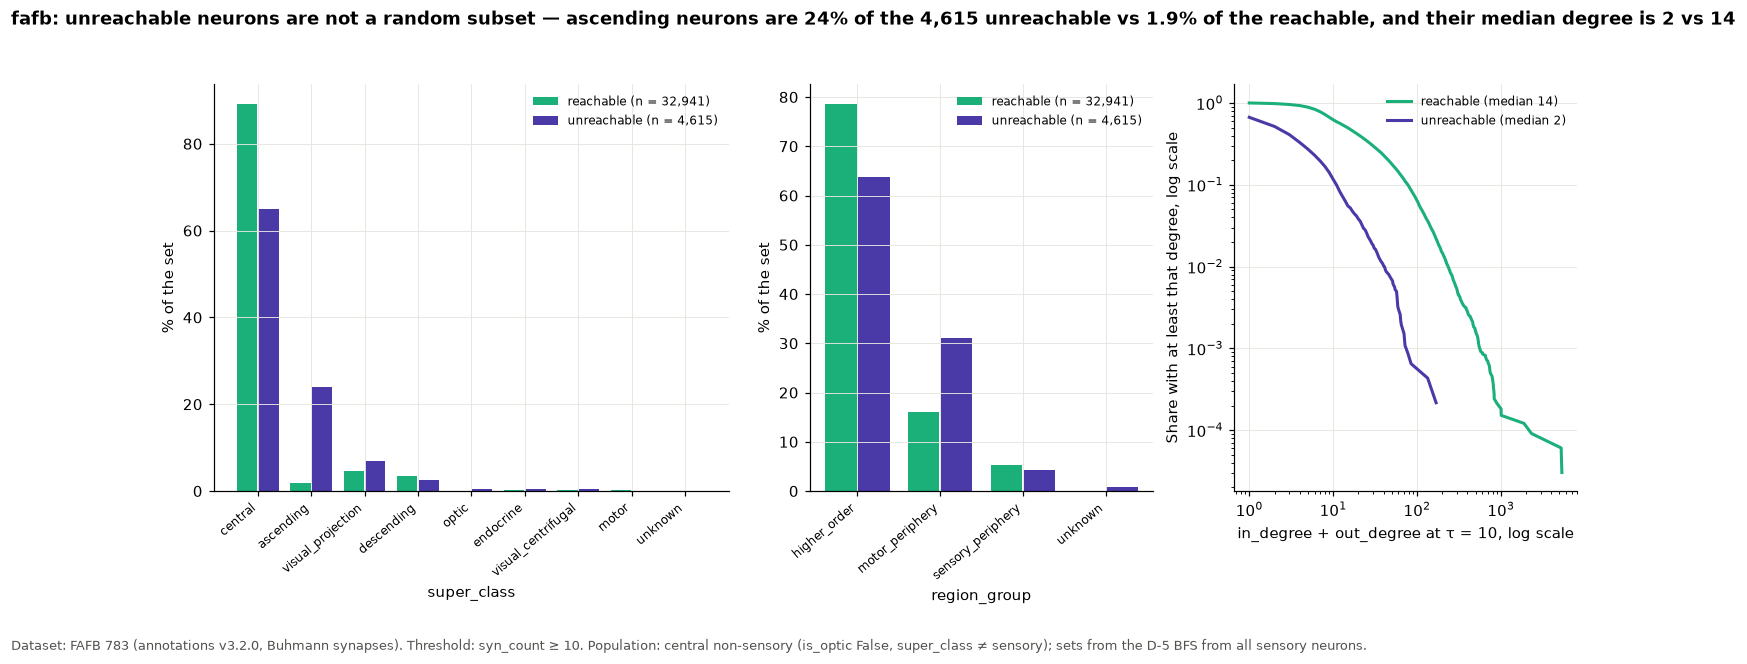

saved figures/eda/D-6_malecns_v1.0_central_min10.png


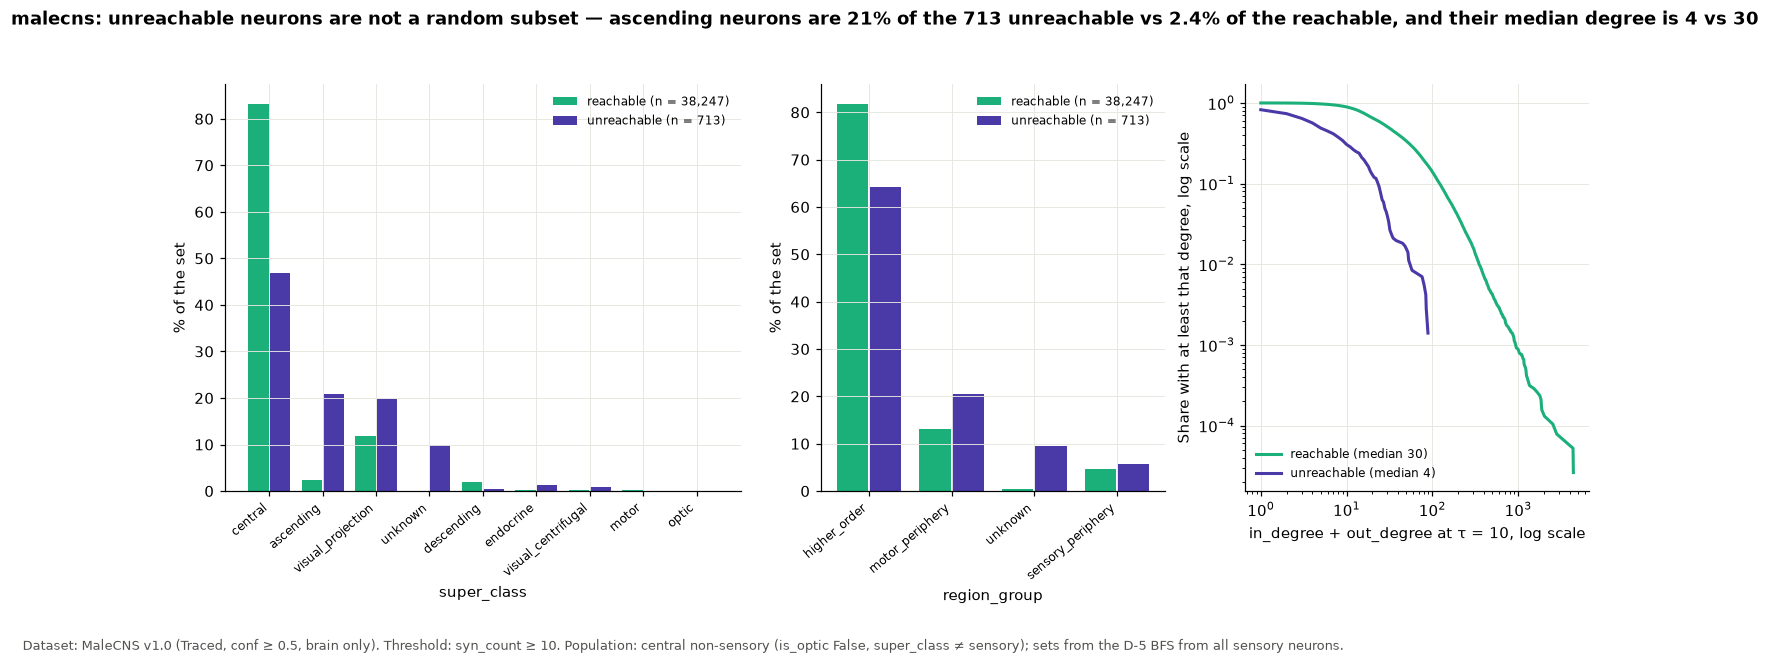

,dataset,set,neurons,median_total_degree,zero_total_degree_%,p90
0,fafb,reachable,32941,14.0,0.00,77.0
1,fafb,unreachable,4615,2.0,33.24,10.0
2,malecns,reachable,38247,30.0,0.00,121.0
3,malecns,unreachable,713,4.0,17.53,23.0


In [11]:
comp_rows, deg_rows = [], []
for ds, d in DATA.items():
    n = d["neurons"]
    F = F10[ds].set_index("neuron_id").reindex(n.neuron_id)
    target = (~n.is_optic & (n.super_class != "sensory")).to_numpy()
    depth = DEPTH[(ds, TAU)]
    T = n[target].copy()
    T["set"] = np.where(depth[target] >= 0, "reachable", "unreachable")
    T["total_degree"] = (F["in_degree"] + F["out_degree"]).to_numpy()[target]
    sizes = T["set"].value_counts()
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
    for ax, col in zip(axes[:2], ["super_class", "region_group"]):
        C = (T.groupby(["set", T[col].astype(str)]).size().unstack(0, fill_value=0)
             .reindex(columns=["reachable", "unreachable"], fill_value=0))
        P = 100 * C / C.sum()
        P = P.loc[P.max(axis=1).sort_values(ascending=False).index]
        for _, r in P.reset_index().melt(id_vars=col, var_name="set", value_name="pct").iterrows():
            comp_rows.append({"dataset": ds, "by": col, "value": r[col], "set": r["set"], "pct": r["pct"],
                              "neurons": int(C.loc[r[col], r["set"]])})
        x = np.arange(len(P))
        for k, s in enumerate(["reachable", "unreachable"]):
            ax.bar(x + (k - 0.5) * 0.4, P[s], width=0.38, color=SET_COL[s], label=f"{s} (n = {sizes.get(s, 0):,})")
        ax.set_xticks(x, P.index, rotation=40, ha="right", fontsize=8)
        ax.set(ylabel="% of the set", xlabel=col)
        ax.legend(fontsize=8, frameon=False)
    ax = axes[2]
    for s in ["reachable", "unreachable"]:
        v = T.loc[T["set"] == s, "total_degree"]
        if len(v):
            x, y = ccdf(v)
            ax.plot(x, y, color=SET_COL[s], label=f"{s} (median {v.median():.0f})")
            deg_rows.append({"dataset": ds, "set": s, "neurons": len(v), "median_total_degree": v.median(),
                             "zero_total_degree_%": 100 * (v == 0).mean(), "p90": v.quantile(0.9)})
    ax.set(xscale="log", yscale="log", xlabel="in_degree + out_degree at τ = 10, log scale",
           ylabel="Share with at least that degree, log scale")
    ax.legend(fontsize=8, frameon=False)
    un = T[T["set"] == "unreachable"]
    share = (T.groupby("set").super_class.value_counts(normalize=True).unstack(0, fill_value=0) * 100)
    over = (share["unreachable"] - share["reachable"]).idxmax()
    fig.suptitle(f"{ds}: unreachable neurons are not a random subset — {over} neurons are "
                 f"{share.loc[over, 'unreachable']:.0f}% of the {len(un):,} unreachable vs "
                 f"{share.loc[over, 'reachable']:.1f}% of the reachable, and their median degree is "
                 f"{un.total_degree.median():.0f} vs {T.loc[T['set']=='reachable','total_degree'].median():.0f}",
                 y=1.02, fontsize=11.5, fontweight="bold")
    caption(fig, f"Dataset: {d['label']}. Threshold: syn_count ≥ 10. Population: central non-sensory "
            "(is_optic False, super_class ≠ sensory); sets from the D-5 BFS from all sensory neurons.", y=-0.17)
    save(fig, f"D-6_{d['tag']}_central_min10.png")
    plt.show()
D6C = pd.DataFrame(comp_rows)
D6C.round(2).to_csv(TAB / "D-6_composition.csv", index=False)
D6D = pd.DataFrame(deg_rows)
D6D.round(2).to_csv(TAB / "D-6_total_degree.csv", index=False)
D6D.round(2)

In [12]:
D6C[D6C.by == "super_class"].pivot_table(index=["dataset", "value"], columns="set", values="pct").round(1)

set                         reachable  unreachable
dataset value                                     
fafb    ascending                 1.9         24.1
        central                  89.2         65.0
        descending                3.6          2.6
        endocrine                 0.2          0.4
        motor                     0.3          0.1
        optic                     0.0          0.5
        unknown                   0.0          0.0
        visual_centrifugal        0.2          0.4
        visual_projection         4.6          7.0
malecns ascending                 2.4         20.9
        central                  83.2         46.8
        descending                2.0          0.4
        endocrine                 0.2          1.3
        motor                     0.3          0.0
        optic                     0.0          0.0
        unknown                   0.0         10.0
        visual_centrifugal        0.1          0.8
        visual_projection        11.8         19.8

## D-7. Reciprocity against a null
Edges at τ = 10. Per region: edges whose two neurons share that region (the stored `region` column;
unknown and UNASGD excluded), reciprocity = share of edges i→j for which j→i also exists (`reciprocity`
from eda_shared). Null: `randomise_edges` on the whole graph at τ = 10, seeds 0–19, same calculation per region.
The 20 regions with most edges are shown.

In [13]:
NOT_REGION = {"unknown", "UNASGD"}
rec_rows, null_rows, run_info = [], [], []
for ds, d in DATA.items():
    E = kept(d["edges"], TAU)[["pre_id", "post_id"]].reset_index(drop=True)
    region = d["neurons"].set_index("neuron_id")["region"]

    def per_region(edges):
        rp, rq = region.reindex(edges.pre_id).to_numpy(), region.reindex(edges.post_id).to_numpy()
        same = edges[(rp == rq)].assign(r=rp[rp == rq])
        return same[~same.r.isin(NOT_REGION)]

    obs = per_region(E)
    top20 = obs.r.value_counts().head(20)
    for r_, n_ in top20.items():
        rec_rows.append({"dataset": ds, "region": r_, "edges": int(n_),
                         "observed": reciprocity(obs[obs.r == r_])})
    rec_rows.append({"dataset": ds, "region": "(whole graph)", "edges": len(E), "observed": reciprocity(E)})
    for seed in range(20):
        t0 = time.perf_counter()
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            R, stats = randomise_edges(E, seed=seed, return_stats=True)
        run_info.append({"dataset": ds, "seed": seed, "seconds": round(time.perf_counter() - t0, 1),
                         **stats, "warning": "; ".join(str(x.message) for x in w)})
        nr = per_region(R)
        for r_ in top20.index:
            null_rows.append({"dataset": ds, "region": r_, "seed": seed, "null": reciprocity(nr[nr.r == r_])})
        null_rows.append({"dataset": ds, "region": "(whole graph)", "seed": seed, "null": reciprocity(R)})
RUNS = pd.DataFrame(run_info)
RUNS.to_csv(TAB / "D-7_randomiser_runs.csv", index=False)
NULL = pd.DataFrame(null_rows)
NULL.to_csv(TAB / "D-7_null_by_seed.csv", index=False)
D7 = pd.DataFrame(rec_rows).merge(
    NULL.groupby(["dataset", "region"]).null.agg(null_mean="mean", null_lo=lambda v: v.quantile(0.025),
                                                  null_hi=lambda v: v.quantile(0.975)).reset_index(),
    on=["dataset", "region"])
D7["above_null"] = D7.observed > D7.null_hi
D7["ratio_obs_null"] = D7.observed / D7.null_mean
D7.round(4).to_csv(TAB / "D-7_reciprocity.csv", index=False)
print(RUNS.groupby("dataset")[["seconds", "accepted_swaps", "target_swaps", "rounds"]].agg(["mean", "min", "max"]))
print("warnings:", RUNS.warning[RUNS.warning != ""].unique()[:3])

        seconds             accepted_swaps                     target_swaps                     rounds        
           mean   min   max           mean       min       max         mean       min       max   mean min max
dataset                                                                                                       
fafb      5.770   5.5   6.3    10950630.15  10949432  10951594   10668220.0  10668220  10668220   21.0  21  21
malecns  13.985  13.6  15.3    22060850.40  22059989  22062484   21381130.0  21381130  21381130   21.0  21  21
warnings: []


saved figures/eda/D-7_fafb_783_malecns_v1.0_all_min10.png


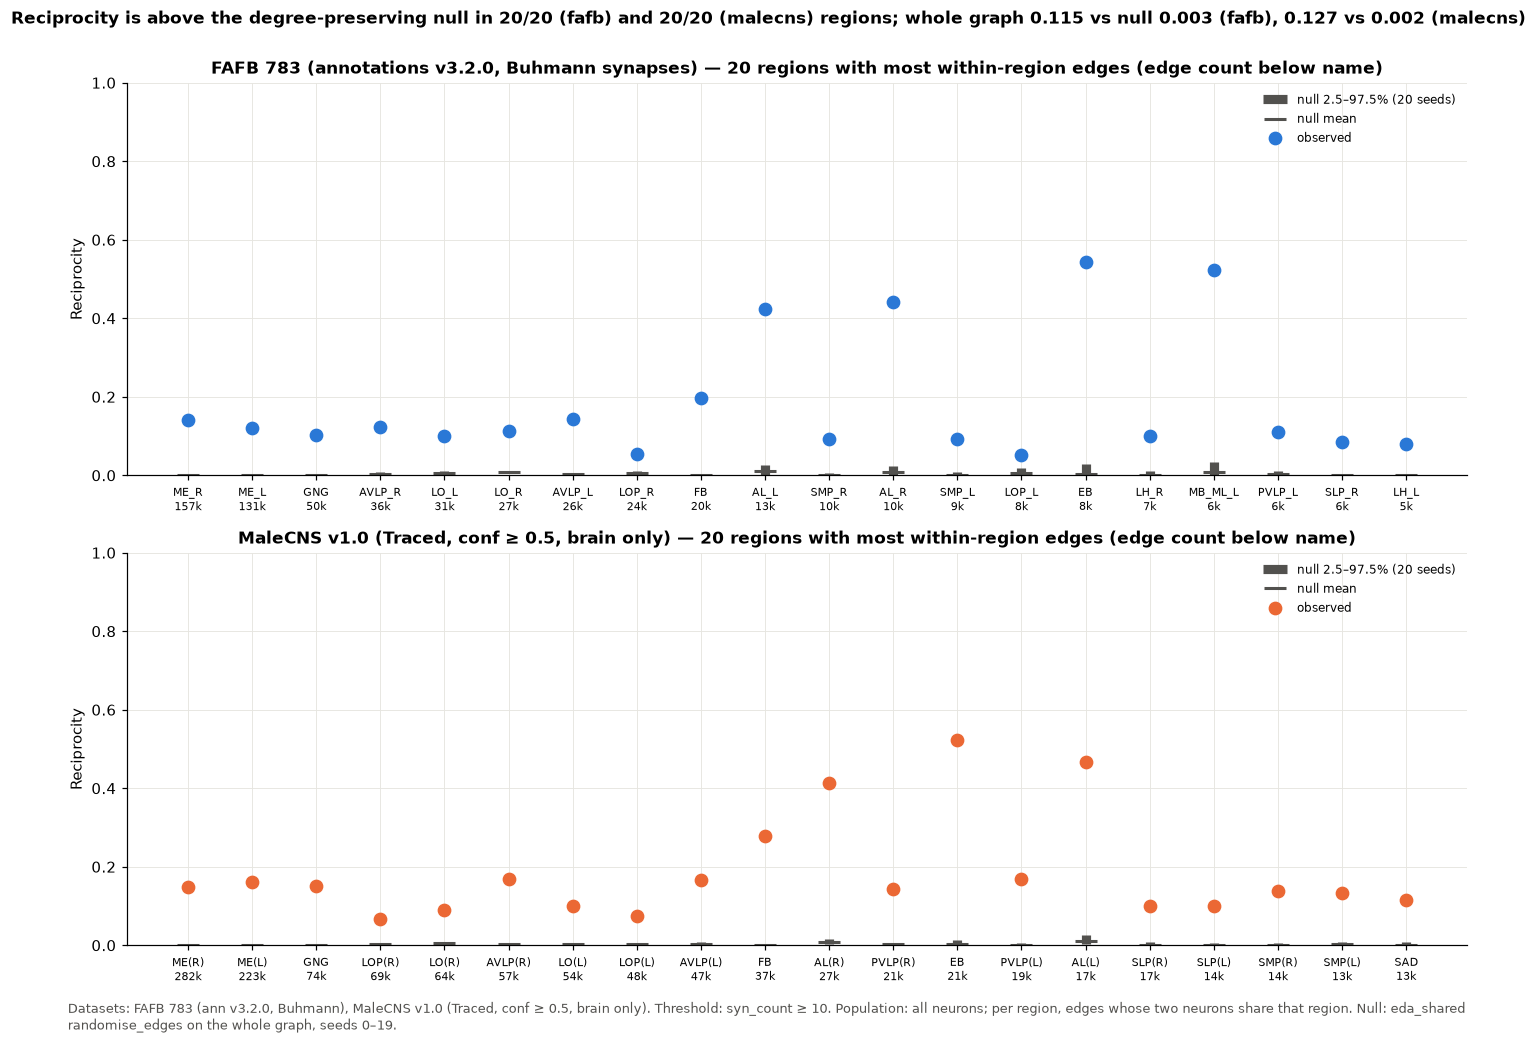

,dataset,region,edges,observed,null_mean,null_lo,null_hi,above_null,ratio_obs_null
0,fafb,ME_R,157378,0.140,0.000,0.000,0.001,True,345.252
1,fafb,ME_L,130771,0.122,0.000,0.000,0.000,True,457.533
2,fafb,GNG,49764,0.102,0.001,0.000,0.002,True,107.689
3,fafb,AVLP_R,36458,0.124,0.004,0.001,0.007,True,29.928
4,fafb,LO_L,30578,0.100,0.007,0.002,0.011,True,14.849
5,fafb,LO_R,26914,0.112,0.007,0.005,0.011,True,15.004
6,fafb,AVLP_L,26455,0.145,0.003,0.001,0.006,True,43.214
7,fafb,LOP_R,23632,0.055,0.006,0.002,0.011,True,8.841
8,fafb,FB,19870,0.196,0.000,0.000,0.004,True,455.351
9,fafb,AL_L,12920,0.424,0.012,0.000,0.026,True,36.588


In [14]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))
for ax, ds in zip(axes, DATA):
    T = D7[(D7.dataset == ds) & (D7.region != "(whole graph)")].sort_values("edges", ascending=False)
    x = np.arange(len(T))
    ax.vlines(x, T.null_lo, T.null_hi, color="#52514e", lw=6, label="null 2.5–97.5% (20 seeds)")
    ax.plot(x, T.null_mean, "_", color="#52514e", ms=14, mew=2, label="null mean")
    ax.plot(x, T.observed, "o", color=DS_COL[ds], ms=8, label="observed")
    ax.set_xticks(x, [f"{r}\n{e/1000:.0f}k" for r, e in zip(T.region, T.edges)], fontsize=7.5)
    ax.set(ylim=(0, 1), ylabel="Reciprocity", title=f"{DATA[ds]['label']} — 20 regions with most within-region edges (edge count below name)")
    ax.legend(fontsize=8, frameon=False, loc="upper right")
W = D7[D7.region == "(whole graph)"].set_index("dataset")
above = D7[D7.region != "(whole graph)"].groupby("dataset").above_null.sum()
fig.suptitle(f"Reciprocity is above the degree-preserving null in {above['fafb']}/20 (fafb) and {above['malecns']}/20 "
             f"(malecns) regions; whole graph {W.loc['fafb','observed']:.3f} vs null {W.loc['fafb','null_mean']:.3f} (fafb), "
             f"{W.loc['malecns','observed']:.3f} vs {W.loc['malecns','null_mean']:.3f} (malecns)",
             y=1.0, fontsize=11, fontweight="bold")
caption(fig, "Datasets: FAFB 783 (ann v3.2.0, Buhmann), MaleCNS v1.0 (Traced, conf ≥ 0.5, brain only). Threshold: "
        "syn_count ≥ 10. Population: all neurons; per region, edges whose two neurons share that region. "
        "Null: eda_shared randomise_edges on the whole graph, seeds 0–19.", y=0.0)
fig.tight_layout()
save(fig, "D-7_fafb_783_malecns_v1.0_all_min10.png")
plt.show()
D7.round(3)

## D-7b. Reciprocity against a region-preserving null (added after the week 3 session)
The D-7 null rewires edges across the whole brain, so it removes the fact that neurons connect where their
arbors meet: at τ = 10 most edges join two neurons of the same region, while in the D-7 null few do, and the
per-region null values come from small, different edge sets. Here each edge belongs to a block
(region of pre neuron, region of post neuron) and swaps pair only edges of the same block
(`src/region_null.py`). Every neuron keeps its exact out-degree to each target region and in-degree from each
source region; partners are re-drawn only among neurons of those regions. Same checks as `randomise_edges`
(no self-connection, no existing edge, no edge proposed twice), 10 accepted swaps per edge per block,
seeds 0–19. Per-region reciprocity uses the same edge sets as D-7 (both ends in region R), so observed, the
D-7 null and this null are compared on identical definitions. D-7 itself is unchanged.

Limitation: "region" is each neuron's single primary neuropil. A finer variant would block each edge by the
neuropil holding its synapses (edgeroi); not done here.

In [15]:
from src.region_null import block_diagnostics, randomise_edges_by_block, region_blocks

new_rows, block_runs, block_tables = [], [], []
for ds, d in DATA.items():
    E = kept(d["edges"], TAU)[["pre_id", "post_id"]].reset_index(drop=True)
    region = d["neurons"].set_index("neuron_id")["region"]
    blocks = region_blocks(E, region)
    top20 = D7[(D7.dataset == ds) & (D7.region != "(whole graph)")].region.tolist()

    def per_region(edges):
        rp, rq = region.reindex(edges.pre_id).to_numpy(), region.reindex(edges.post_id).to_numpy()
        same = edges[(rp == rq)].assign(r=rp[rp == rq])
        return same[~same.r.isin(NOT_REGION)]

    for seed in range(20):
        t0 = time.perf_counter()
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            R, stats, per_block = randomise_edges_by_block(E, blocks, seed=seed, return_stats=True)
        block_runs.append({"dataset": ds, "seed": seed, "seconds": round(time.perf_counter() - t0, 1), **stats,
                           "warning": "; ".join(str(x.message) for x in w)})
        if seed == 0:                       # mixing check per block: density and share of edges changed
            diag = block_diagnostics(E, R, blocks).merge(
                per_block[["block", "accepted_swaps", "target_swaps", "reached_target", "no_alternative"]], on="block")
            block_tables.append(diag.assign(dataset=ds))
        nr = per_region(R)
        for r_ in top20:
            new_rows.append({"dataset": ds, "region": r_, "seed": seed, "null": reciprocity(nr[nr.r == r_])})
        new_rows.append({"dataset": ds, "region": "(whole graph)", "seed": seed, "null": reciprocity(R)})

BRUNS = pd.DataFrame(block_runs)
BRUNS.to_csv(TAB / "D-7b_regionnull_runs.csv", index=False)
BLOCKS = pd.concat(block_tables, ignore_index=True)
BLOCKS.to_csv(TAB / "D-7b_block_mixing_seed0.csv", index=False)
NEWNULL = pd.DataFrame(new_rows)
NEWNULL.to_csv(TAB / "D-7b_null_by_seed.csv", index=False)

agg = NEWNULL.groupby(["dataset", "region"]).null.agg(
    new_null_mean="mean", new_null_lo=lambda v: v.quantile(0.025), new_null_hi=lambda v: v.quantile(0.975)).reset_index()
D7B = (D7.rename(columns={"null_mean": "old_null_mean", "null_lo": "old_null_lo", "null_hi": "old_null_hi",
                          "ratio_obs_null": "old_ratio", "above_null": "above_old_null"})
       .merge(agg, on=["dataset", "region"]))
D7B["new_ratio"] = D7B.observed / D7B.new_null_mean
D7B["above_new_null"] = D7B.observed > D7B.new_null_hi
D7B["inside_new_band"] = (D7B.observed >= D7B.new_null_lo) & (D7B.observed <= D7B.new_null_hi)

# Mixing check (seed 0) for each region's within-region block R|R; whole graph = edge-weighted over all blocks.
# The null is informative where the block reached its swap target and at least half its edges changed.
diag_rows = []
for ds in DATA:
    Bd = BLOCKS[BLOCKS.dataset == ds]
    for r_ in D7B[D7B.dataset == ds].region:
        if r_ == "(whole graph)":
            x = {"block_density": np.nan, "block_acc_over_target": Bd.accepted_swaps.sum() / Bd.target_swaps.sum(),
                 "block_share_changed": np.average(Bd.share_changed, weights=Bd.edges)}
        else:
            b = Bd[Bd.block == f"{r_}|{r_}"].iloc[0]
            x = {"block_density": b.density, "block_acc_over_target": b.accepted_swaps / b.target_swaps,
                 "block_share_changed": b.share_changed}
        diag_rows.append({"dataset": ds, "region": r_, **x})
D7B = D7B.merge(pd.DataFrame(diag_rows), on=["dataset", "region"])
D7B["null_informative"] = (D7B.block_acc_over_target >= 1) & (D7B.block_share_changed >= 0.5)
D7B = D7B[["dataset", "region", "edges", "observed", "old_null_mean", "old_null_lo", "old_null_hi", "old_ratio",
           "above_old_null", "new_null_mean", "new_null_lo", "new_null_hi", "new_ratio", "above_new_null",
           "inside_new_band", "block_density", "block_acc_over_target", "block_share_changed", "null_informative"]]
D7B.round(4).to_csv(TAB / "D-7b_reciprocity_regionnull.csv", index=False)

mix = BRUNS.groupby("dataset").agg(seconds=("seconds", "mean"), rounds=("rounds", "mean"),
                                    blocks=("blocks", "first"), edges_unswappable=("edges_unswappable", "first"),
                                    share_edges_unreached=("share_edges_unreached", "mean"),
                                    edges_unreached=("edges_unreached", "mean"),
                                    edges_unreached_no_alternative=("edges_unreached_no_alternative", "mean"))
print(mix.round(4))
print("total runtime (s):", BRUNS.groupby("dataset").seconds.sum().to_dict())
print("regions where the region-preserving null is not informative (poor mixing):")
print(D7B[~D7B.null_informative][["dataset", "region", "block_density", "block_acc_over_target", "block_share_changed"]])
D7B.round(3)

         seconds  rounds  blocks  edges_unswappable  share_edges_unreached  edges_unreached  edges_unreached_no_alternative
dataset                                                                                                                    
fafb      16.235   220.0    2746                324                 0.0161         17182.25                           790.0
malecns   39.000   220.0    3156                283                 0.0136         29117.45                          1214.0
total runtime (s): {'fafb': 324.7, 'malecns': 780.0}
regions where the region-preserving null is not informative (poor mixing):
   dataset   region  block_density  block_acc_over_target  block_share_changed
16    fafb  MB_ML_L       0.002206               0.508285             0.209861


,dataset,region,edges,observed,old_null_mean,old_null_lo,old_null_hi,old_ratio,above_old_null,new_null_mean,new_null_lo,new_null_hi,new_ratio,above_new_null,inside_new_band,block_density,block_acc_over_target,block_share_changed,null_informative
0,fafb,ME_R,157378,0.140,0.000,0.000,0.001,345.252,True,0.002,0.001,0.002,83.119,True,False,0.000,1.028,0.995,True
1,fafb,ME_L,130771,0.122,0.000,0.000,0.000,457.533,True,0.001,0.001,0.002,99.201,True,False,0.000,1.030,0.995,True
2,fafb,GNG,49764,0.102,0.001,0.000,0.002,107.689,True,0.013,0.011,0.013,8.174,True,False,0.005,1.034,0.973,True
3,fafb,AVLP_R,36458,0.124,0.004,0.001,0.007,29.928,True,0.039,0.037,0.041,3.170,True,False,0.010,1.013,0.932,True
4,fafb,LO_L,30578,0.100,0.007,0.002,0.011,14.849,True,0.030,0.028,0.032,3.319,True,False,0.001,1.027,0.930,True
5,fafb,LO_R,26914,0.112,0.007,0.005,0.011,15.004,True,0.035,0.033,0.037,3.185,True,False,0.001,1.019,0.947,True
6,fafb,AVLP_L,26455,0.145,0.003,0.001,0.006,43.214,True,0.047,0.045,0.049,3.105,True,False,0.010,1.015,0.925,True
7,fafb,LOP_R,23632,0.055,0.006,0.002,0.011,8.841,True,0.040,0.036,0.043,1.369,True,False,0.002,1.012,0.920,True
8,fafb,FB,19870,0.196,0.000,0.000,0.004,455.351,True,0.025,0.022,0.027,7.977,True,False,0.009,1.005,0.947,True
9,fafb,AL_L,12920,0.424,0.012,0.000,0.026,36.588,True,0.212,0.204,0.218,1.999,True,False,0.012,1.011,0.723,True


saved figures/eda/D-7b_fafb_783_malecns_v1.0_all_min10.png


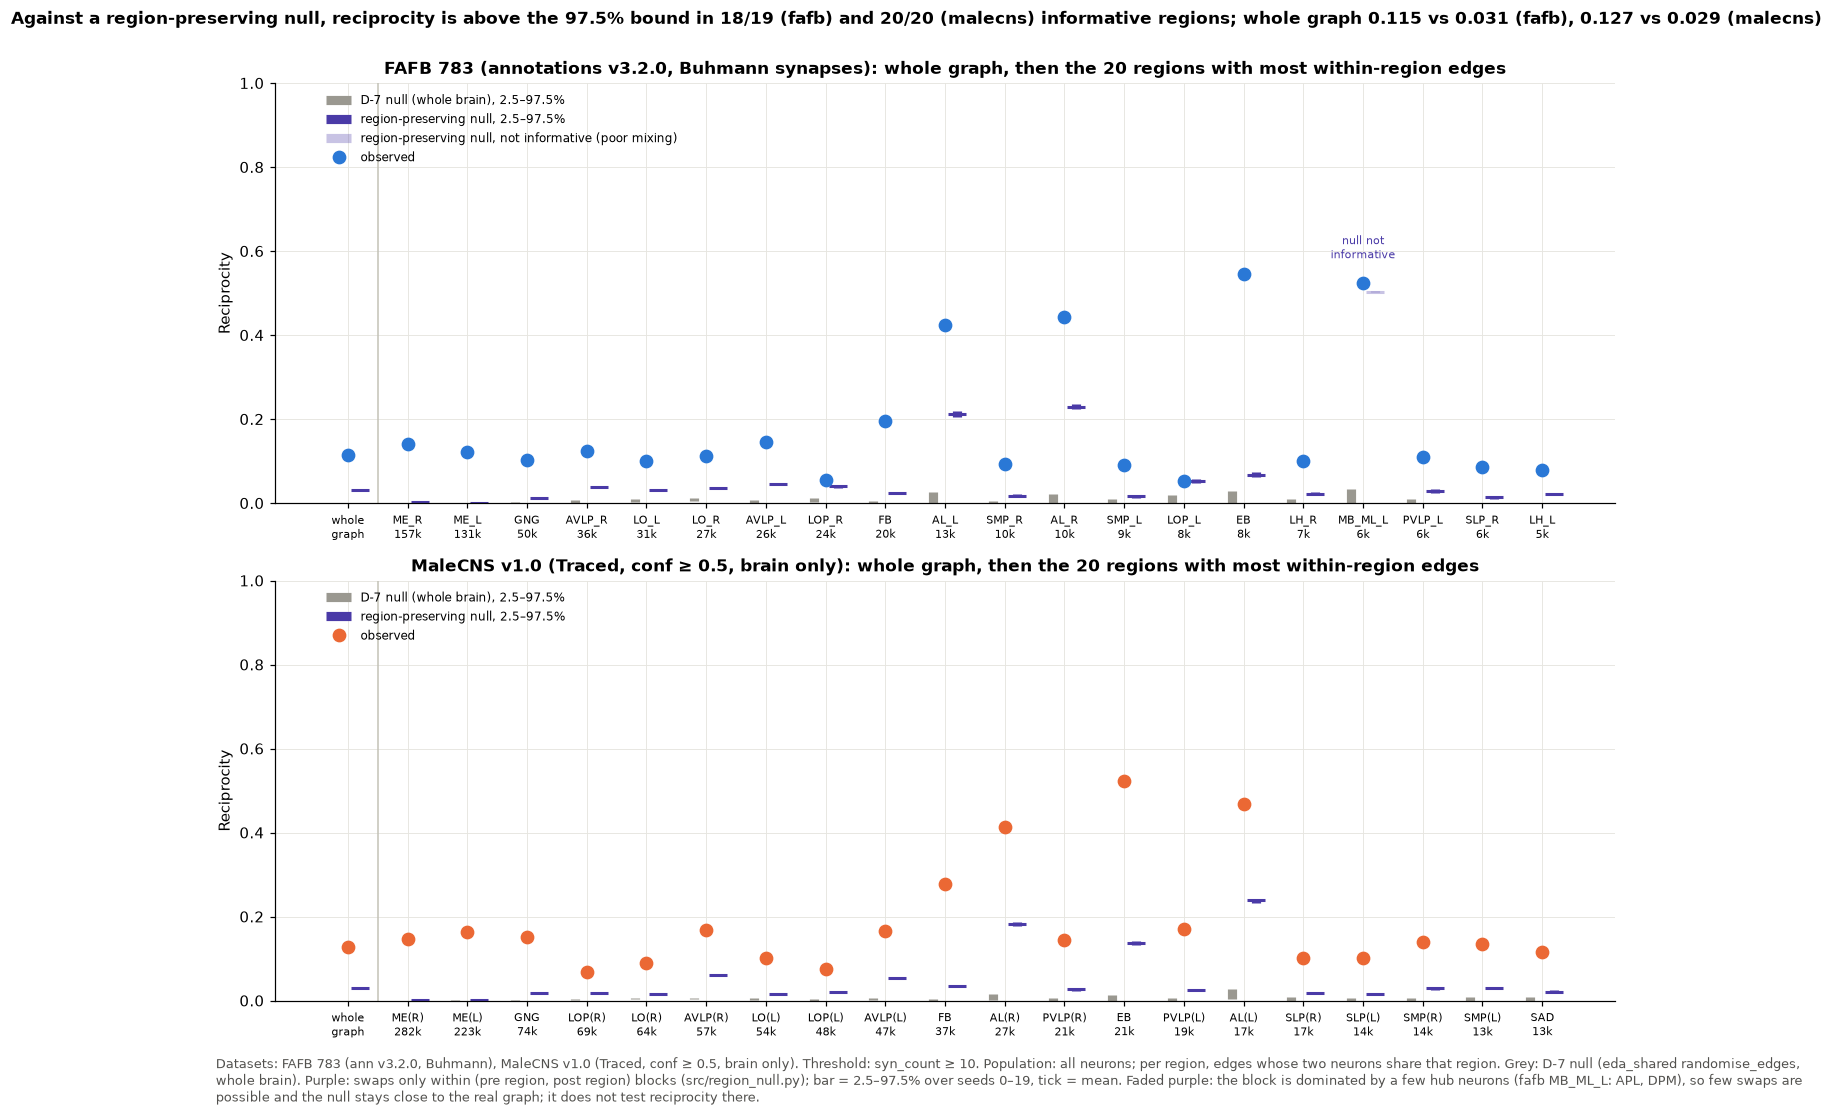

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9.5))
NEW_COL = "#4a3aa7"
for ax, ds in zip(axes, DATA):
    T = D7B[D7B.dataset == ds]
    T = pd.concat([T[T.region == "(whole graph)"], T[T.region != "(whole graph)"].sort_values("edges", ascending=False)])
    x = np.arange(len(T))
    ax.vlines(x - 0.2, T.old_null_lo, T.old_null_hi, color="#9a9890", lw=6, label="D-7 null (whole brain), 2.5–97.5%")
    inf = T.null_informative.to_numpy()
    ax.vlines(x[inf] + 0.2, T.new_null_lo[inf], T.new_null_hi[inf], color=NEW_COL, lw=6,
              label="region-preserving null, 2.5–97.5%")
    ax.plot(x[inf] + 0.2, T.new_null_mean[inf], "_", color=NEW_COL, ms=12, mew=2)
    if (~inf).any():
        ax.vlines(x[~inf] + 0.2, T.new_null_lo[~inf], T.new_null_hi[~inf], color=NEW_COL, lw=6, alpha=0.3,
                  label="region-preserving null, not informative (poor mixing)")
        ax.plot(x[~inf] + 0.2, T.new_null_mean[~inf], "_", color=NEW_COL, ms=12, mew=2, alpha=0.3)
        for xi, top in zip(x[~inf], np.maximum(T.observed[~inf], T.new_null_hi[~inf])):
            ax.text(xi, top + 0.05, "null not\ninformative", ha="center", va="bottom", fontsize=7.5, color=NEW_COL)
    ax.plot(x, T.observed, "o", color=DS_COL[ds], ms=8, label="observed", zorder=3)
    ax.axvline(0.5, color="#c3c2b7", lw=1)
    labels = ["whole\ngraph"] + [f"{r}\n{e/1000:.0f}k" for r, e in zip(T.region[1:], T.edges[1:])]
    ax.set_xticks(x, labels, fontsize=7.5)
    ax.set(ylim=(0, 1), ylabel="Reciprocity",
           title=f"{DATA[ds]['label']}: whole graph, then the 20 regions with most within-region edges")
    ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(0.03, 1.0))
W = D7B[D7B.region == "(whole graph)"].set_index("dataset")
Rg = D7B[(D7B.region != "(whole graph)") & D7B.null_informative]
above, n_inf = Rg.groupby("dataset").above_new_null.sum(), Rg.groupby("dataset").size()
fig.suptitle(f"Against a region-preserving null, reciprocity is above the 97.5% bound in {above['fafb']}/{n_inf['fafb']} "
             f"(fafb) and {above['malecns']}/{n_inf['malecns']} (malecns) informative regions; whole graph {W.loc['fafb','observed']:.3f} vs "
             f"{W.loc['fafb','new_null_mean']:.3f} (fafb), {W.loc['malecns','observed']:.3f} vs "
             f"{W.loc['malecns','new_null_mean']:.3f} (malecns)", y=1.0, fontsize=11, fontweight="bold")
caption(fig, "Datasets: FAFB 783 (ann v3.2.0, Buhmann), MaleCNS v1.0 (Traced, conf ≥ 0.5, brain only). Threshold: "
        "syn_count ≥ 10. Population: all neurons; per region, edges whose two neurons share that region. Grey: D-7 null "
        "(eda_shared randomise_edges, whole brain). Purple: swaps only within (pre region, post region) blocks "
        "(src/region_null.py); bar = 2.5–97.5% over seeds 0–19, tick = mean. Faded purple: the block is dominated by a "
        "few hub neurons (fafb MB_ML_L: APL, DPM), so few swaps are possible and the null stays close to the real graph; "
        "it does not test reciprocity there.", y=0.0)
fig.tight_layout()
save(fig, "D-7b_fafb_783_malecns_v1.0_all_min10.png")
plt.show()